# Lab 03 Tasks — Geometric Transformations

Every task uses its own image from the `images/` folder (Wikimedia Commons and OpenCV sample photos).

Where a scenario starts from a "damaged" picture (rotated, slanted, glitched…), the code first **simulates** that damage on the real photo, then **fixes** it with a hand-built matrix.

**Matrix hierarchy used in this lab**

| Level | Matrix | Keeps |
|---|---|---|
| Linear | 2x2 (scale, rotation, shear) | origin fixed |
| Affine | 3x3 with last row `[0 0 1]` (adds translation) | parallel lines |
| Projective | full 3x3 (homography) | straight lines only |

In [1]:
%pip install opencv-python matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\azama\AppData\Local\Temp\claude\C--Users-azama-VS-Code-PROJECTS-01-Academic-Projects-Computer-Vision\a3c19062-200d-4788-a4f3-77cf48e11a00\scratchpad\venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True, precision=3)   # print matrices as plain decimals


def show(images, titles, size=5):
    # Helper: shows several images side by side (BGR images are converted to RGB for Matplotlib).
    plt.figure(figsize=(size * len(images), size))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(title, fontsize=13)
        plt.axis('off')
    plt.show()


def to_affine(A2x2, t=(0, 0)):
    # Helper: puts a 2x2 linear matrix and a translation (tx, ty) into one 3x3 homogeneous matrix.
    M = np.eye(3)
    M[:2, :2] = A2x2
    M[:2, 2] = t
    return M


def T(tx, ty):
    # 3x3 translation matrix: moves every pixel by (tx, ty).
    return np.array([[1, 0, tx],
                     [0, 1, ty],
                     [0, 0, 1]], dtype=float)


def R(deg):
    # 2x2 rotation matrix built from sine and cosine (angle in degrees).
    a = np.radians(deg)
    return np.array([[np.cos(a), -np.sin(a)],
                     [np.sin(a),  np.cos(a)]])

## Task 1: The Tiny Fingerprint (Linear - Scale)

Scaling matrix:
 [[3 0]
 [0 3]] 
Translation to stay centred: [-675. -450.]


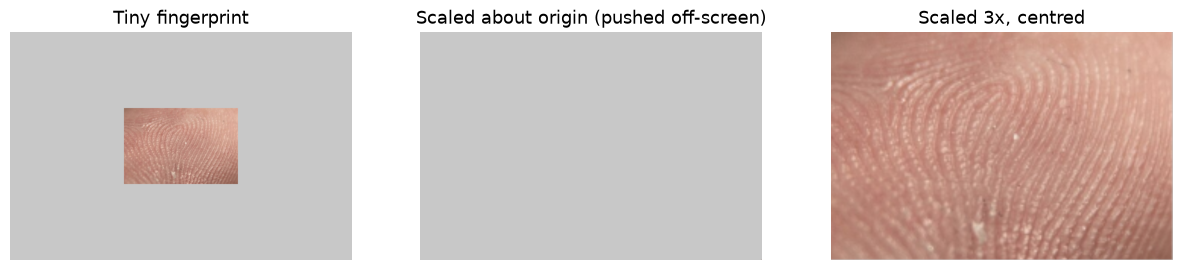

In [3]:
img = cv2.imread('images/task1_fingerprint.jpg')

# Simulate the problem: cut out the fingerprint and shrink it so it is too small to read,
# then place it in the middle of a 675x450 "screen".
tiny = cv2.resize(img[320:620, 415:865], (225, 150))
screen = np.full((450, 675, 3), 200, dtype=np.uint8)
screen[150:300, 225:450] = tiny

# 2x2 scaling matrix: 300% on x and 300% on y.
S = np.array([[3, 0],
              [0, 3]])

# Scaling alone grows the image away from the top-left corner (origin), so the print drifts off-centre.
naive = cv2.warpAffine(screen, to_affine(S)[:2], (675, 450))

# Keep it centred: the screen centre c must stay where it is after scaling.
# S*c + t = c  ->  t = c - S*c
c = np.array([675 / 2, 450 / 2])
t = c - S @ c
print("Scaling matrix:\n", S, "\nTranslation to stay centred:", t)
centred = cv2.warpAffine(screen, to_affine(S, t)[:2], (675, 450))

show([screen, naive, centred], ['Tiny fingerprint', 'Scaled about origin (pushed off-screen)', 'Scaled 3x, centred'])

## Task 2: The Dizzy Satellite (Linear - Rotation)

Original size: (640, 480) | Tilted canvas: (792, 792) | Restored canvas: (1120, 1120)


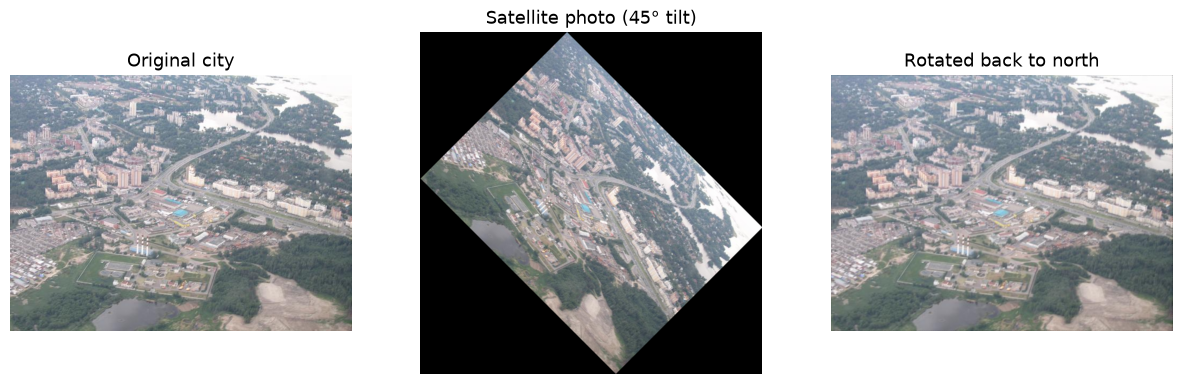

In [4]:
def rotate_full(img, deg):
    # Rotates an image about its centre with a hand-made rotation matrix
    # and enlarges the canvas so no corner gets chopped off.
    h, w = img.shape[:2]
    Rm = R(deg)
    cos, sin = abs(Rm[0, 0]), abs(Rm[1, 0])

    # New size = projection of the old width and height onto the new axes.
    new_w = int(round(w * cos + h * sin))
    new_h = int(round(w * sin + h * cos))

    # Translation so the old centre lands on the new centre: t = new_c - R*old_c
    t = np.array([new_w / 2, new_h / 2]) - Rm @ np.array([w / 2, h / 2])
    return cv2.warpAffine(img, to_affine(Rm, t)[:2], (new_w, new_h)), (new_w, new_h)


city = cv2.imread('images/task2_aerial_city.jpg')

# Simulate the bumped satellite: city photo is tilted by 45 degrees.
tilted, _ = rotate_full(city, 45)

# Spin it back to true north with the opposite angle.
fixed, new_size = rotate_full(tilted, -45)

# Crop the original-sized city from the centre of the restored canvas (removes the black padding).
y0, x0 = (fixed.shape[0] - city.shape[0]) // 2, (fixed.shape[1] - city.shape[1]) // 2
fixed = fixed[y0:y0 + city.shape[0], x0:x0 + city.shape[1]]
print("Original size:", city.shape[1::-1], "| Tilted canvas:", tilted.shape[1::-1], "| Restored canvas:", new_size)

show([city, tilted, fixed], ['Original city', 'Satellite photo (45° tilt)', 'Rotated back to north'])

## Task 3: The Fast Train Barcode (Linear - Shear)

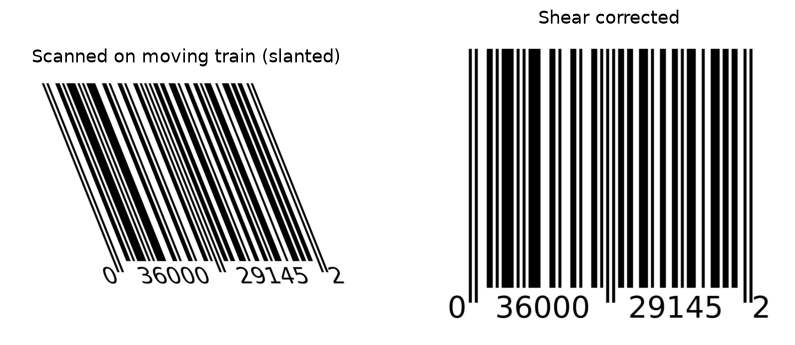

In [5]:
barcode = cv2.imread('images/task3_barcode.jpg')
h, w = barcode.shape[:2]
k = 0.4   # shear factor: how much each row is pushed sideways

# Shear matrix: x' = x + k*y  (lower rows are pushed further to the right -> slanted look).
Sh = np.array([[1, k],
               [0, 1]])
slanted = cv2.warpAffine(barcode, to_affine(Sh)[:2], (int(w + k * h), h), borderValue=(255, 255, 255))

# Opposite shear pushes the pixels back: x = x' - k*y
Sh_fix = np.array([[1, -k],
                   [0,  1]])
fixed = cv2.warpAffine(slanted, to_affine(Sh_fix)[:2], (w, h), borderValue=(255, 255, 255))

show([slanted, fixed], ['Scanned on moving train (slanted)', 'Shear corrected'])

## Task 4: The Hidden Treasure Map (Affine - Translation)

Translation matrix:
 [[  1.   0. 150.]
 [  0.   1.  80.]
 [  0.   0.   1.]]


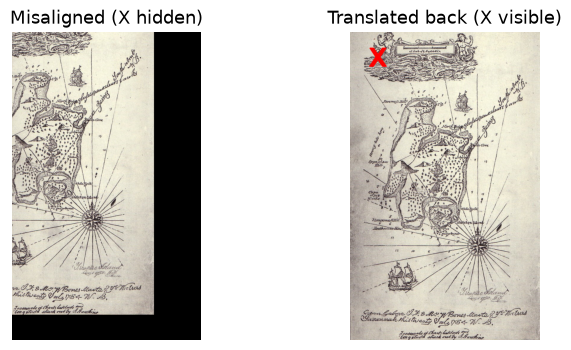

In [6]:
map_img = cv2.resize(cv2.imread('images/task4_treasure_map.jpg'), (600, 973))
h, w = map_img.shape[:2]

# Mark the treasure near the top-left of the map.
cv2.putText(map_img, 'X', (60, 110), cv2.FONT_HERSHEY_SIMPLEX, 3, (0, 0, 255), 8)

# The misaligned screen: the map sits 150 px too far left and 80 px too far up, so the X is off-screen.
misaligned = T(-150, -80)
screen_before = cv2.warpAffine(map_img, misaligned[:2], (w, h))

# 3x3 translation matrix that slides every pixel 150 right and 80 down.
fix = T(150, 80)
print("Translation matrix:\n", fix)

# Apply the fix on top of the misalignment (matrix multiplication combines both moves).
screen_after = cv2.warpAffine(map_img, (fix @ misaligned)[:2], (w, h))

show([screen_before, screen_after], ['Misaligned (X hidden)', 'Translated back (X visible)'], size=4)

## Task 5: The Robot's Assembly Line (Rigid Transformation)

Rigid matrix:


 [[   0.    1.   67.]
 [  -1.    0. 1053.]
 [   0.    0.    1.]]


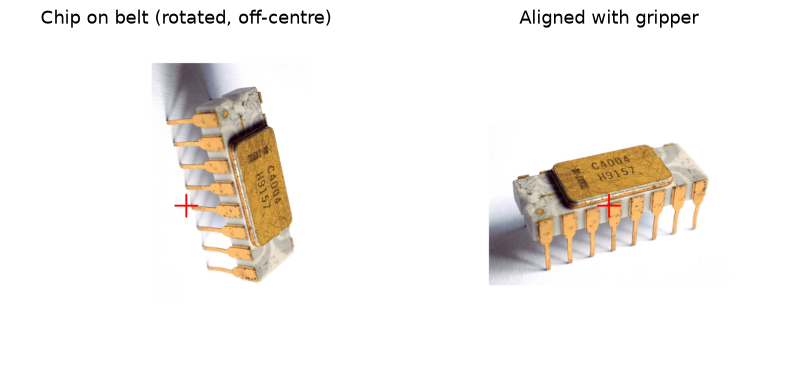

In [7]:
# Half size + white border so the chip has room to rotate on the "belt".
chip = cv2.imread('images/task5_microchip.jpg')
chip = cv2.copyMakeBorder(cv2.resize(chip, None, fx=0.5, fy=0.5), 250, 250, 150, 150,
                          cv2.BORDER_CONSTANT, value=(255, 255, 255))
h, w = chip.shape[:2]
centre = np.array([w / 2, h / 2])          # gripper position = centre of the belt image

# Simulate the belt: chip rotated sideways (90°) and pushed off-centre by (120, -60).
off = np.array([120, -60])
place = T(*(centre + off)) @ to_affine(R(90)) @ T(*-centre)
on_belt = cv2.warpAffine(chip, place[:2], (w, h), borderValue=(255, 255, 255))

# Rigid transform = Rotation + Translation in ONE 3x3 matrix:
# 1) move the chip centre to the origin, 2) rotate back by -90°, 3) move it to the gripper centre.
rigid = T(*centre) @ to_affine(R(-90)) @ T(*-(centre + off))
print("Rigid matrix:\n", rigid.round(3))
aligned = cv2.warpAffine(on_belt, rigid[:2], (w, h), borderValue=(255, 255, 255))

# Draw the gripper crosshair at the target position.
for im in (on_belt, aligned):
    cv2.drawMarker(im, tuple(centre.astype(int)), (0, 0, 255), cv2.MARKER_CROSS, 60, 4)

show([on_belt, aligned], ['Chip on belt (rotated, off-centre)', 'Aligned with gripper'])

## Task 6: The Architect's Blueprint (Similarity Transformation)

Similarity matrix:
 [[    2.474     1.429 -2864.871]
 [   -1.429     2.474    49.885]
 [    0.        0.        1.   ]]


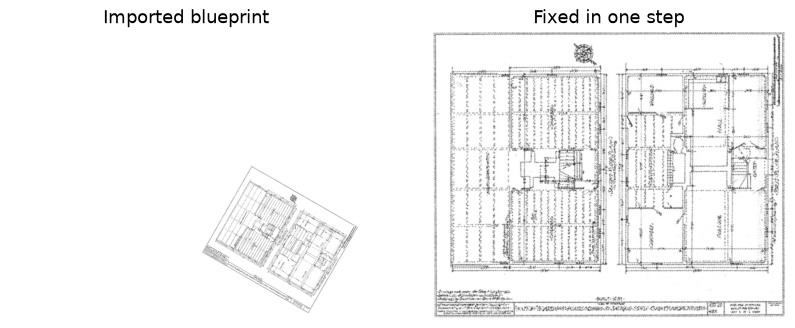

In [8]:
plan = cv2.imread('images/task6_floor_plan.jpg')
h, w = plan.shape[:2]
centre = np.array([w / 2, h / 2])

# Simulate the bad import: 35% size, rotated 30°, stuck in the bottom-right corner.
s, ang, corner = 0.35, 30, np.array([w - 300, h - 285])
bad = T(*corner) @ to_affine(s * R(ang)) @ T(*-centre)
imported = cv2.warpAffine(plan, bad[:2], (w, h), borderValue=(255, 255, 255))

# Similarity = Scale + Rotation + Translation in ONE matrix (angles kept, size changed):
# move the small plan's centre to origin -> undo rotation and scale -> move to canvas centre.
similarity = T(*centre) @ to_affine((1 / s) * R(-ang)) @ T(*-corner)
print("Similarity matrix:\n", similarity.round(3))
fixed = cv2.warpAffine(imported, similarity[:2], (w, h), borderValue=(255, 255, 255))

show([imported, fixed], ['Imported blueprint', 'Fixed in one step'])

## Task 7: The Glitched Image (General Affine Transformation)

Start points:
 [[100.  80.]
 [450.  60.]
 [300. 300.]] 
End points:
 [[218.33 144.32]
 [555.97 220.3 ]
 [416.28 356.8 ]]
Recovered affine matrix:
 [[  0.966   0.022 120.   ]
 [  0.259   0.731  60.   ]
 [  0.      0.      1.   ]]


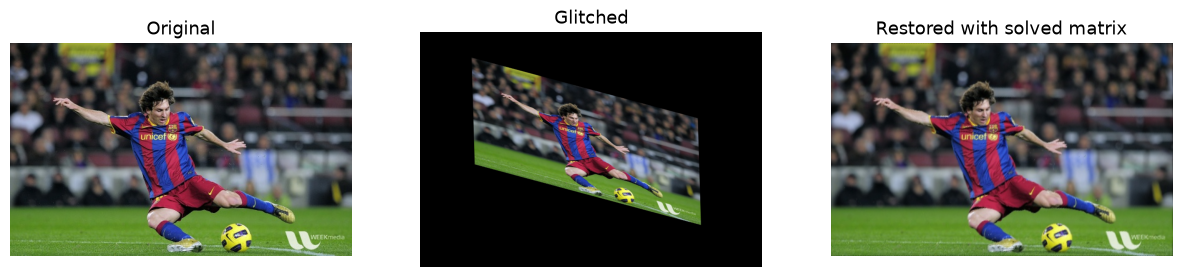

In [9]:
photo = cv2.imread('images/task7_football_photo.jpg')
h, w = photo.shape[:2]

# Simulate the corrupted transmission: squish + slant + rotate + move, all at once.
glitch = T(120, 60) @ to_affine(R(15)) @ to_affine([[1, 0.3], [0, 1]]) @ to_affine([[1, 0], [0, 0.7]])
glitched = cv2.warpAffine(photo, glitch[:2], (800, 550))

# Three landmarks: where they are in the clean photo (start) and in the glitched photo (end).
start = np.array([[100, 80], [450, 60], [300, 300]], dtype=float)
end = (glitch @ np.c_[start, np.ones(3)].T).T[:, :2]   # the "given" end coordinates
print("Start points:\n", start, "\nEnd points:\n", end.round(2))

# Each point gives 2 equations:  x' = a*x + b*y + c   and   y' = d*x + e*y + f
# 3 points -> 6 equations -> solve for the 6 unknowns [a b c d e f].
A, B = [], []
for (x, y), (xp, yp) in zip(start, end):
    A.append([x, y, 1, 0, 0, 0]); B.append(xp)
    A.append([0, 0, 0, x, y, 1]); B.append(yp)
a, b, c, d, e, f = np.linalg.solve(np.array(A), np.array(B))
affine = np.array([[a, b, c], [d, e, f], [0, 0, 1]])
print("Recovered affine matrix:\n", affine.round(3))

# The recovered matrix maps clean -> glitched, so its inverse fixes the image.
restored = cv2.warpAffine(glitched, np.linalg.inv(affine)[:2], (w, h))

show([photo, glitched, restored], ['Original', 'Glitched', 'Restored with solved matrix'])

## Task 8: The Sidewalk Illusion (Projective - Perspective)

Perspective matrix:
 [[  -1.898   -0.815 1564.641]
 [  -0.      -2.851 1995.933]
 [  -0.      -0.002    1.   ]]


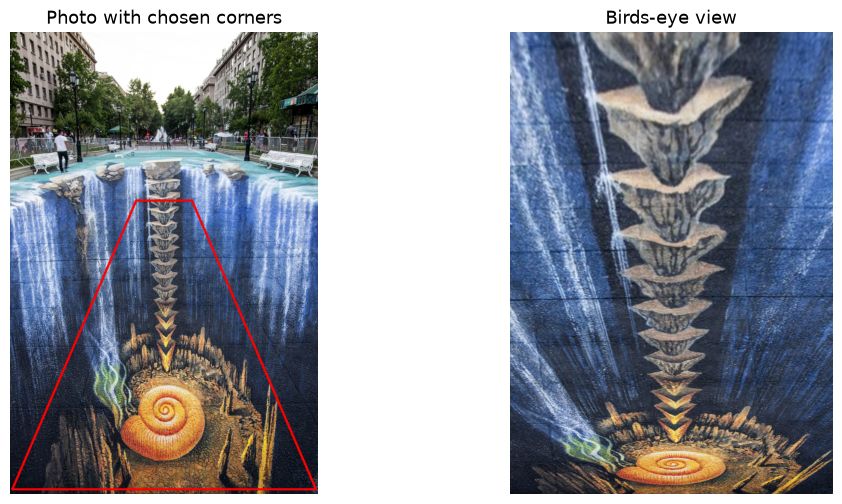

In [10]:
art = cv2.imread('images/task8_chalk_art.jpg')

# 4 corners on the ground that form a rectangle in reality (they follow the street's
# converging lines towards the vanishing point). Order: top-left, top-right, bottom-right, bottom-left.
src = np.float32([[524, 700], [756, 700], [1271, 1900], [9, 1900]])

# Where those corners should go in the top-down view: a perfect rectangle.
out_w, out_h = 700, 1000
dst = np.float32([[0, 0], [out_w, 0], [out_w, out_h], [0, out_h]])

# Perspective (projective) matrix: 8 unknowns solved from the 4 point pairs.
P = cv2.getPerspectiveTransform(src, dst)
print("Perspective matrix:\n", P.round(4))
birds_eye = cv2.warpPerspective(art, P, (out_w, out_h))

marked = art.copy()
cv2.polylines(marked, [src.astype(np.int32)], True, (0, 0, 255), 8)
show([marked, birds_eye], ['Photo with chosen corners', "Birds-eye view"], size=6)

## Task 9: The Stadium Panorama (Projective - Homography)

Homography matrix:
 [[  1.153  -0.017 521.221]
 [  0.032   1.085 -25.277]
 [  0.     -0.      1.   ]]


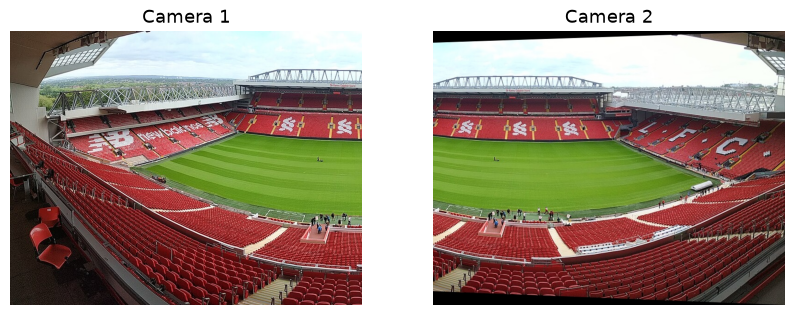

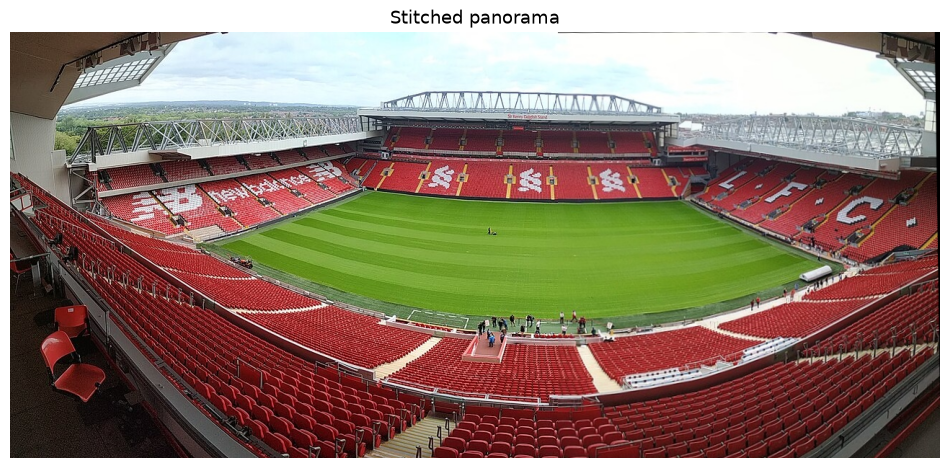

In [11]:
left = cv2.imread('images/task9_camera_left.jpg')
right = cv2.imread('images/task9_camera_right.jpg')

# 4 matching points in the shared middle area (read off both images with an image viewer).
pts_left = np.float32([[560, 120], [740, 140], [730, 470], [570, 500]])
pts_right = np.float32([[36, 133], [205, 149], [195, 456], [46, 480]])

# Homography that projects the right camera's view into the left camera's space.
H = cv2.getPerspectiveTransform(pts_right, pts_left)
print("Homography matrix:\n", H.round(4))

# Warp the right image onto a wide canvas, then lay the left image on top of it.
h, w = left.shape[:2]
panorama = cv2.warpPerspective(right, H, (w + right.shape[1], h))
panorama[:, :w] = left

# Crop the empty black strip on the right side.
cols = np.where(panorama.max(axis=(0, 2)) > 0)[0]
panorama = panorama[:, :cols[-1]]

show([left, right], ['Camera 1', 'Camera 2'])
show([panorama], ['Stitched panorama'], size=12)

## Task 10: The Master Forger (Full Hierarchy Challenge)

Final combined matrix:
 [[  0.297  -0.01  679.942]
 [  0.002   0.246 110.096]
 [  0.     -0.      1.019]]


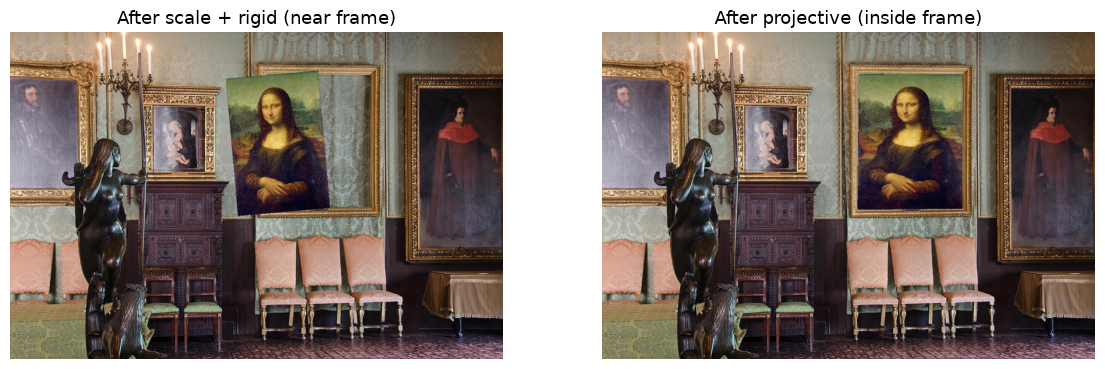

In [12]:
painting = cv2.imread('images/task10_painting.jpg')
wall = cv2.imread('images/task10_museum_wall.jpg')
ph, pw = painting.shape[:2]
wh, ww = wall.shape[:2]

# Inner corners of the empty frame on the wall (TL, TR, BR, BL).
frame = np.float32([[667, 108], [936, 109], [936, 457], [663, 460]])

# Step 1 - Linear Scale: shrink the painting to 25%.
S = to_affine(np.diag([0.25, 0.25]))

# Step 2 - Rigid: small rotation + move it next to the frame.
rigid = T(560, 120) @ to_affine(R(-5))

# Where the painting's 4 corners are after scale + rigid.
corners = np.float32([[0, 0], [pw, 0], [pw, ph], [0, ph]])
moved = cv2.perspectiveTransform(corners.reshape(-1, 1, 2), rigid @ S).reshape(-1, 2)

# Step 3 - Projective: warp those 4 corners exactly onto the frame corners.
P = cv2.getPerspectiveTransform(moved, frame)

def paste(M):
    # Warps the painting with matrix M onto the wall and pastes it using a mask.
    warped = cv2.warpPerspective(painting, M, (ww, wh))
    mask = cv2.warpPerspective(np.full((ph, pw), 255, np.uint8), M, (ww, wh))
    out = wall.copy()
    out[mask > 0] = warped[mask > 0]
    return out

# Full hierarchy in one matrix: Projective x Rigid x Scale.
full = P @ rigid @ S
print("Final combined matrix:\n", full.round(4))

show([paste(rigid @ S), paste(full)], ['After scale + rigid (near frame)', 'After projective (inside frame)'], size=7)